# PREPROCESAMIENTO

In [348]:
import numpy as np
import pandas as pd
import os
import seaborn as sns
import matplotlib.pyplot as plt
import scipy.stats as stats 
import missingno as msno
from sklearn.impute import KNNImputer
from sklearn.preprocessing import PolynomialFeatures, RobustScaler
from sklearn.linear_model import LassoCV
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.feature_selection import SelectFromModel
from sklearn.ensemble import RandomForestRegressor


## Carga de datos del dataset completo

In [297]:
FILENAME = "dataset_consolidado_complete.csv"
datapath_completo = os.path.join("..","..","data","clean",FILENAME)
df_completo = pd.read_csv(datapath_completo)


C:\Users\ireni\AppData\Local\Temp\ipykernel_43420\1541478545.py:3: DtypeWarning: Columns (154: Nivel Silo Bagazo Norte (1), 178: KW Trafo 8, 336: Totalizador Bba P1, 337: Totalizador Bba P2, 338: Totalizador Bba P4, 339: Totalizador Bba Envasado, 340: Totalizador Bba P51) have mixed types. Specify dtype option on import or set low_memory=False.
  df_completo = pd.read_csv(datapath_completo)


In [298]:
df_completo = df_completo.replace(' ', np.nan)
columnas_numericas = ~df_completo.columns.isin(["DIA", "HORA"])
df_completo.loc[:, columnas_numericas] = (
    df_completo.loc[:, columnas_numericas]
    .apply(pd.to_numeric, errors="coerce")
)

## Creacion del dataframe diario

Para la creación del dataset diario se tuvo en cuenta: los días completos (aquellos que llegaron a las 23:59 horas) y los días con reinicio en el consumo de frío.

Además, mediante conocimiento del dominio y EDA se filtraron como primera pasada algunas variables.  

In [299]:
df_temp = df_completo.groupby('DIA').last().reset_index()
hora_cierre = '23:59:00'
df_diario = df_temp[df_temp['HORA'] == hora_cierre].copy()


dias_eliminados = len(df_temp) - len(df_diario)
print(f"Se eliminaron {dias_eliminados} días incompletos que no llegaron a las 23:59.")

fecha_siguiente = pd.to_datetime(df_diario["DIA"].shift(-1))
fecha_actual = pd.to_datetime(df_diario["DIA"])
diferencia_dia_siguiente = fecha_siguiente - fecha_actual
indices_a_borrar = df_diario.index[diferencia_dia_siguiente > pd.Timedelta(days=1)]
df_diario = df_diario.drop(index=indices_a_borrar)
df_diario['target_Frio_kW_next'] = df_diario['Frio (Kw)'].shift(-1)

df_diario = df_diario.dropna(subset=['target_Frio_kW_next']).copy()

#Features a utilizar (conocimiento del dominio)

features_a_utilizar = [
    "DIA",
    "KW Mycom 1",
    "KW Mycom 2",
    "KW Mycom 3",
    "KW Mycom 4",
    "KW Mycom 5",
    "KW Mycom 6",
    "KW Mycom 7",
    "EE Frio / Hl",
    "KW Bba Glicol Sala MAq",
    "KW Bba Glicol Bod",
    "KW Enfr Agua Cocina",
    "Hl de Mosto",
    "Hl Producido Bodega",
    "Hl Cerveza Filtrada",
    "Hl Cerveza Envasada",
    "Hl Cerveza Cocina",
    "Elaboracion (Kw)",
    "Bodega (Kw)",
    "Envasado (Kw)",
    "Servicios (Kw)",
    "Frio (Kw)",
    "Agua Planta (Hl)",
    "Agua Helada Cocina",
    "Glicol Paste L3",
    "Temp Tq Intermedio",
    "Gas Planta (Mj)",
    "Vapor Elaboracion (Kg)",
    "Totalizador_Bodega",
    "Totalizador_Tq_Pulmon",
    "Tot Fermantacion_Cocina",
    "Tot Reposo Inferior",
    "Tot  Reposo Superior",
    "Tot  Trasiego",
    "Tot A10/20",
    "Tot A40/240/50/60/Centec/Filtro",
    "Tot  A130/330/430",
    "Tot L3, L4 y Planta de CO2",
    # Variables agregadas tras realizar EDA
    "Agua Cond REC",
    "KW Gral Planta",
    "Planta (Kw)",
    "Sala Maq (Kw)",
    "KW Trafo 4",
    "KW Trafo 5", 
    'KW Trafo 8', 
    'KW Trafo 11', 
    'KW Trafo 12',
    'KW Trafo 9', 
    'KW Trafo 10',
    "KW Cond 5. 6 y 9",
    "Produccion (Hl)",
    "Aire Producido (M3)",
    "Totalizador Sistema Kaeser"
]

df_completo["HORA"] = df_completo["HORA"].astype(str)

#días donde el target no se reinicio a las 00:00 (Se obtuvieron del eda)
dias_sin_reinicio = df_completo[(df_completo["HORA"] == "00:00:00") & (df_completo["Frio (Kw)"] != 0)]["DIA"]
df_diario = df_diario.drop(index= df_diario[df_diario["DIA"].isin(dias_sin_reinicio)].index)


target = ["target_Frio_kW_next"]
df_diario = df_diario[features_a_utilizar + target].copy()


Se eliminaron 5 días incompletos que no llegaron a las 23:59.


C:\Users\ireni\AppData\Local\Temp\ipykernel_43420\3907674206.py:1: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  df_temp = df_completo.groupby('DIA').last().reset_index()


## Análisis patron de valores faltantes

Con el objetivo de tratar valores faltantes, primero se realizó una inspección del total de nulos en cada una de las variables y su correlación para posteriormente decidir que tratamiento se optará.
 

In [300]:
tabla_nulos = pd.DataFrame(
    {"Valores Nulos": df_diario.isna().sum(),
     "Porcentaje (%)": df_diario.isna().mean() * 100,
    })

tabla_nulos = (
    tabla_nulos.style.set_caption("Resumen de Valores Nulos por Columna")
    .format({"Porcentaje (%)": "{:.2f}%"})
)

display(tabla_nulos)

,Valores Nulos,Porcentaje (%)
DIA,0,0.00%
KW Mycom 1,0,0.00%
KW Mycom 2,0,0.00%
KW Mycom 3,0,0.00%
KW Mycom 4,0,0.00%
KW Mycom 5,0,0.00%
KW Mycom 6,0,0.00%
KW Mycom 7,0,0.00%
EE Frio / Hl,21,1.81%
KW Bba Glicol Sala MAq,0,0.00%


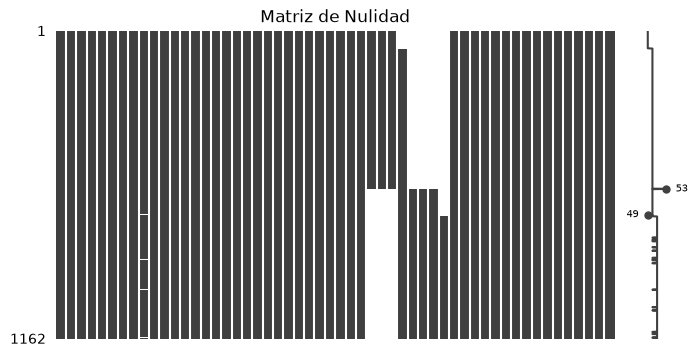

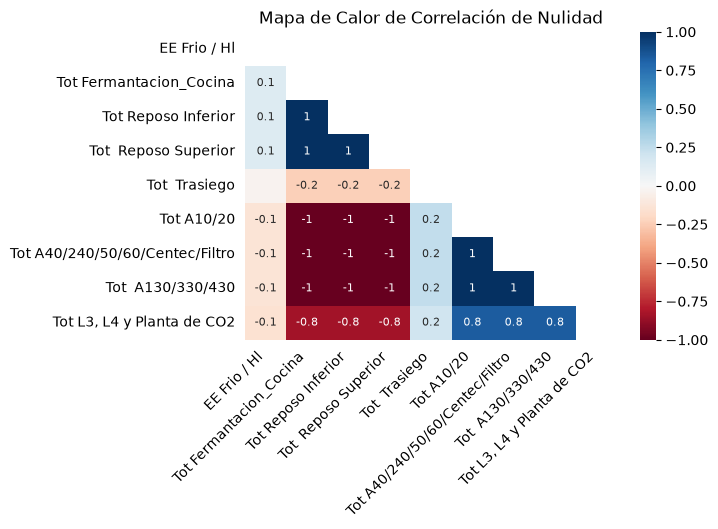

In [301]:
msno.matrix(df_diario, figsize=(8,4), fontsize=8)
plt.title("Matriz de Nulidad")
plt.show()

msno.heatmap(df_diario, figsize=(6,4), fontsize=10)
plt.title("Mapa de Calor de Correlación de Nulidad")
plt.show()

Gracias a la observación de los gráficos, se puede apreciar que las variables con alto porcentajes de valores nulos además presentan una gran correlación de nulidad entre ellas. 
Aquelllas variables donde sus valores superan el 40% de valores nulos se optó por eliminarlas.

In [302]:
pd.set_option("display.max_columns", None)
display(df_diario)

,DIA,KW Mycom 1,KW Mycom 2,KW Mycom 3,KW Mycom 4,KW Mycom 5,KW Mycom 6,KW Mycom 7,EE Frio / Hl,KW Bba Glicol Sala MAq,KW Bba Glicol Bod,KW Enfr Agua Cocina,Hl de Mosto,Hl Producido Bodega,Hl Cerveza Filtrada,Hl Cerveza Envasada,Hl Cerveza Cocina,Elaboracion (Kw),Bodega (Kw),Envasado (Kw),Servicios (Kw),Frio (Kw),Agua Planta (Hl),Agua Helada Cocina,Glicol Paste L3,Temp Tq Intermedio,Gas Planta (Mj),Vapor Elaboracion (Kg),Totalizador_Bodega,Totalizador_Tq_Pulmon,Tot Fermantacion_Cocina,Tot Reposo Inferior,Tot Reposo Superior,Tot Trasiego,Tot A10/20,Tot A40/240/50/60/Centec/Filtro,Tot A130/330/430,"Tot L3, L4 y Planta de CO2",Agua Cond REC,KW Gral Planta,Planta (Kw),Sala Maq (Kw),KW Trafo 4,KW Trafo 5,KW Trafo 8,KW Trafo 11,KW Trafo 12,KW Trafo 9,KW Trafo 10,KW Cond 5. 6 y 9,Produccion (Hl),Aire Producido (M3),Totalizador Sistema Kaeser,target_Frio_kW_next
0,2020-07-01,0,3600.0,0.0,0,0.0,1013.0,4342.0,333.139535,467.0,1990.0,0.0,0.0,43.000,0.0,86.0,0.00,2027.25,2968.00,594.0,23848.0,14325.0,10280.000000,0.0,0.0,-3.0,150775.730528,6779.44000,733.3100,1775.0,570.17,6323.06,0.1,NaN,NaN,NaN,NaN,NaN,231.210000,29529.0,27637.270000,17080.0,2636.0,1124.0,1186.56,11920.0,3639.0,1637.75,6046.25,614.0,2398.000000,31871.0,31871.0,23954.0
1,2020-07-02,701,5848.0,1362.0,2238,0.0,1062.0,5641.0,3.419545,777.0,2359.0,5.0,2907.0,7005.025,13361.0,10667.0,3343.05,5391.13,5595.88,16522.0,38033.0,23954.0,13970.000000,3452.0,0.0,1.0,469499.449248,45103.22000,5484.0600,14295.0,694.08,5349.47,0.8,NaN,NaN,NaN,NaN,NaN,284.210000,65592.0,54409.810000,27216.0,5792.0,1654.0,3095.53,18592.0,7248.0,17288.75,10108.13,1073.0,25148.500000,51079.0,51079.0,28268.0
2,2020-07-03,328,5980.0,5356.0,3321,0.0,1043.0,4792.0,3.787626,824.0,2615.0,13.0,4829.0,7463.250,9493.0,10024.0,4902.50,6437.75,6237.50,14818.0,42565.5,28268.0,36300.000000,5495.0,0.0,-1.0,548270.265952,61087.32000,5146.2300,8366.0,400.66,4965.47,0.5,NaN,NaN,NaN,NaN,NaN,297.530000,68039.0,65685.590000,31386.0,6863.0,1665.5,1404.94,18486.0,11349.0,17260.75,9177.75,1083.0,29365.000000,62958.0,62958.0,24246.0
3,2020-07-04,0,6040.0,1407.0,5029,0.0,325.0,4901.0,1.870213,765.0,1891.0,28.0,7828.0,12964.300,8450.0,12223.0,13705.60,5694.25,4810.75,18696.0,39650.0,24246.0,40120.000000,8376.0,0.0,2.0,635538.945472,80588.95000,3575.0800,5081.0,447.89,5040.93,1.0,NaN,NaN,NaN,NaN,NaN,279.630000,69857.0,67098.540000,28070.0,7489.0,1648.0,6043.81,20510.0,7586.0,18709.50,6717.25,1031.0,32150.800000,69435.0,69435.0,29885.0
4,2020-07-05,0,6381.0,2043.0,5501,0.0,2568.0,6222.0,3.354482,786.0,2406.0,21.0,6406.0,8908.975,12894.0,8358.0,9459.95,7148.25,6394.75,14831.0,45385.0,29885.0,38940.000000,7971.0,0.0,-2.0,553697.930928,78034.90000,4823.7500,12559.0,400.06,5690.25,0.2,NaN,NaN,NaN,NaN,NaN,282.030000,73431.0,70600.640000,33463.0,7249.0,1645.0,5820.25,22212.0,8410.0,15220.50,9527.25,1077.0,30793.900000,66431.0,66431.0,24449.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1183,2023-10-20,3549,0.0,0.0,576,1279.0,0.0,960.0,NaN,1198.0,2985.0,0.0,0.0,0.000,1541.0,0.0,0.00,3976.00,4619.00,515.0,20273.0,11931.0,12257.954102,0.0,0.0,0.0,167237.171455,9852.87500,858.6250,2369.0,NaN,NaN,NaN,1458.1875,330.125,1636.750,6879.625,76.40625,85.300781,28064.0,26515.660000,14490.0,2162.0,4143.0,492.0,10640.0,60.0,1900.00,7582.00,323.0,5435.917969,19749.0,19749.0,9481.0
1184,2023-10-21,129,0.0,1736.0,0,1954.0,0.0,196.0,NaN,1041.0,2996.0,0.0,0.0,0.000,0.0,0.0,0.00,2383.00,3119.00,452.0,16977.0,9481.0,7468.889160,0.0,0.0,0.0,131153.378545,6476.84375,0.0000,1649.0,NaN,NaN,NaN,0.0000,232.375,2194.000,6922.250,40.12500,68.298828,22953.0,21627.800000,9793.0,3979.0,4788.0,492.5,3216.0,1754.0,1778.00,5818.00,330.0,2979.067383,15961.0,15961.0,11587.0
1185,2023-10-22,0,0.0,0.0,0,4094.0,0.0,1814.0,2.782861,1344.0,2920.0,0.0,3978.0,4163.700,0.0,1167.0,7160.40,3200.00,2788.00,2758.0,208

In [303]:
df_con_nulos =  df_diario.isna().mean() * 100 
columnas_con_nulos = df_con_nulos[df_con_nulos > 40].index

df_diario = df_diario.drop(columns=columnas_con_nulos)

### Variables Mycoms y Trafos

In [304]:
mycoms = df_diario.columns[df_diario.columns.str.contains("Mycom")]
df_diario["Kw Mycom Mean"] = df_diario.loc[:, mycoms].mean(axis=1, skipna=True)
df_diario = df_diario.drop(columns=mycoms, errors= "ignore")
df_diario.columns

Index(['DIA', 'EE Frio / Hl', 'KW Bba Glicol Sala MAq', 'KW Bba Glicol Bod',
       'KW Enfr Agua Cocina', 'Hl de Mosto', 'Hl Producido Bodega',
       'Hl Cerveza Filtrada', 'Hl Cerveza Envasada', 'Hl Cerveza Cocina',
       'Elaboracion (Kw)', 'Bodega (Kw)', 'Envasado (Kw)', 'Servicios (Kw)',
       'Frio (Kw)', 'Agua Planta (Hl)', 'Agua Helada Cocina',
       'Glicol Paste L3', 'Temp Tq Intermedio', 'Gas Planta (Mj)',
       'Vapor Elaboracion (Kg)', 'Totalizador_Bodega', 'Totalizador_Tq_Pulmon',
       'Tot  Trasiego', 'Agua Cond REC', 'KW Gral Planta', 'Planta (Kw)',
       'Sala Maq (Kw)', 'KW Trafo 4', 'KW Trafo 5', 'KW Trafo 8',
       'KW Trafo 11', 'KW Trafo 12', 'KW Trafo 9', 'KW Trafo 10',
       'KW Cond 5. 6 y 9', 'Produccion (Hl)', 'Aire Producido (M3)',
       'Totalizador Sistema Kaeser', 'target_Frio_kW_next', 'Kw Mycom Mean'],
      dtype='str')

In [305]:
trafos = df_diario.columns[df_diario.columns.str.contains("Trafo")]
df_diario["Kw Trafo Mean"] = df_diario.loc[:, trafos].mean(axis=1, skipna=True) 
df_diario = df_diario.drop(columns=trafos, errors= "ignore")

## Valores con ceros

En el transcurso del EDA, no solamente se observo la existencia de valores nulos en las distintas variables sino que tambien se detectó la presencia de columnas con una gran cantidad de ceros. Es necesario comprender que esto no implica nulidad sin embargo cuando la variable toma en casi su totalidad un unico valor (en este caso cero) la misma no esta brindando información para la predicción del Frío.

Aquellas predictoras en donde mas de la mitad de sus valores son ceros se optó por eliminarlas al ser redundantes para la predicción.

In [306]:
ceros = (df_diario==0).sum().sort_values(ascending=False)/df_diario.shape[0]*100
df_diario = df_diario.drop(columns=ceros[ceros>50].index)

In [307]:
numericas = df_diario.columns[~df_diario.columns.isin(["DIA", "HORA"])]

### Separacion de Datos en train y test

## Tratamiento de nulos


Para aquellas predictoras que aún mantienen valores nulos y no fueron eliminadas, se realizó un tratamiento mediante KNNImputed.

In [308]:
df_numericas = df_diario[numericas].copy()
knn_imputer = KNNImputer(n_neighbors =5)
df_knn_imputed = pd.DataFrame(knn_imputer.fit_transform(df_numericas), columns=df_numericas.columns)


In [309]:
df_knn_imputed["DIA"] = df_diario["DIA"].copy()


In [310]:
df_knn_imputed

,EE Frio / Hl,KW Bba Glicol Sala MAq,KW Bba Glicol Bod,Hl de Mosto,Hl Producido Bodega,Hl Cerveza Filtrada,Hl Cerveza Envasada,Hl Cerveza Cocina,Elaboracion (Kw),Bodega (Kw),Envasado (Kw),Servicios (Kw),Frio (Kw),Agua Planta (Hl),Temp Tq Intermedio,Gas Planta (Mj),Vapor Elaboracion (Kg),Totalizador_Bodega,Totalizador_Tq_Pulmon,Tot Trasiego,Agua Cond REC,KW Gral Planta,Planta (Kw),Sala Maq (Kw),KW Cond 5. 6 y 9,Produccion (Hl),Aire Producido (M3),Totalizador Sistema Kaeser,target_Frio_kW_next,Kw Mycom Mean,Kw Trafo Mean,DIA
0,333.139535,467.0,1990.0,0.0,43.000,0.0,86.0,0.00,2027.25,2968.00,594.0,23848.0,14325.0,10280.000000,-3.0,150775.730528,6779.44000,733.3100,1775.0,98.33575,231.210000,29529.0,27637.270000,17080.0,614.0,2398.000000,31871.0,31871.0,23954.0,1279.285714,4027.080000,2020-07-01
1,3.419545,777.0,2359.0,2907.0,7005.025,13361.0,10667.0,3343.05,5391.13,5595.88,16522.0,38033.0,23954.0,13970.000000,1.0,469499.449248,45103.22000,5484.0600,14295.0,2092.11000,284.210000,65592.0,54409.810000,27216.0,1073.0,25148.500000,51079.0,51079.0,28268.0,2407.428571,9111.201429,2020-07-02
2,3.787626,824.0,2615.0,4829.0,7463.250,9493.0,10024.0,4902.50,6437.75,6237.50,14818.0,42565.5,28268.0,36300.000000,-1.0,548270.265952,61087.32000,5146.2300,8366.0,1119.12200,297.530000,68039.0,65685.590000,31386.0,1083.0,29365.000000,62958.0,62958.0,24246.0,2974.285714,9458.134286,2020-07-03
3,1.870213,765.0,1891.0,7828.0,12964.300,8450.0,12223.0,13705.60,5694.25,4810.75,18696.0,39650.0,24246.0,40120.000000,2.0,635538.945472,80588.95000,3575.0800,5081.0,1551.25800,279.630000,69857.0,67098.540000,28070.0,1031.0,32150.800000,69435.0,69435.0,29885.0,2528.857143,9814.794286,2020-07-04
4,3.354482,786.0,2406.0,6406.0,8908.975,12894.0,8358.0,9459.95,7148.25,6394.75,14831.0,45385.0,29885.0,38940.000000,-2.0,553697.930928,78034.90000,4823.7500,12559.0,1769.86200,282.030000,73431.0,70600.640000,33463.0,1077.0,30793.900000,66431.0,66431.0,24449.0,3245.000000,10012.000000,2020-07-05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1157,79.315336,1198.0,2985.0,0.0,0.000,1541.0,0.0,0.00,3976.00,4619.00,515.0,20273.0,11931.0,12257.954102,0.0,167237.171455,9852.87500,858.6250,2369.0,1458.18750,85.300781,28064.0,26515.660000,14490.0,323.0,5435.917969,19749.0,19749.0,9481.0,909.142857,3854.142857,2023-09-24
1158,76.974643,1041.0,2996.0,0.0,0.000,0.0,0.0,0.00,2383.00,3119.00,452.0,16977.0,9481.0,7468.889160,0.0,131153.378545,6476.84375,0.0000,1649.0,0.00000,68.298828,22953.0,21627.800000,9793.0,330.0,2979.067383,15961.0,15961.0,11587.0,573.571429,3117.928571,2023-09-25
1159,2.782861,1344.0,2920.0,3978.0,4163.700,0.0,1167.0,7160.40,3200.00,2788.00,2758.0,20821.0,11587.0,17313.110352,0.0,295228.456226,35214.46875,7.9375,2863.0,0.00000,67.599609,31956.0,30287.570000,11873.0,328.0,11381.960449,26134.0,26134.0,10123.0,844.000000,4391.071429,2023-09-26
1160,20.765128,1093.0,2983.0,0.0,487.500,0.0,975.0,0.00,2329.00,2882.00,3339.0,18771.0,10123.0,12697.983398,0.0,217570.326705,6922.65625,0.0000,3244.0,0.00000,58.400391,30480.0,28667.480000,10395.0,334.0,5431.079102,22882.0,22882.0,10360.0,657.857143,4142.285714,2023-09-27


## Tratamiento de valores extremos


In [311]:
df_diario_sin_outliers = df_knn_imputed.copy()

for f in numericas: 
    Q1 = df_diario_sin_outliers[f].quantile(0.25)
    Q3 = df_diario_sin_outliers[f].quantile(0.75)
    P99 = df_diario_sin_outliers[f].quantile(0.99)
    IQR = Q3 - Q1

    #no pusimos 1.5 ya que nos parece muy estricto
    outliers = df_diario_sin_outliers[(df_diario_sin_outliers[f] < - 3 * IQR + Q1 ) | (df_diario_sin_outliers[f] >  3 * IQR + Q3 )].index
    
    if f == 'target_Frio_kW_next':
        df_diario_sin_outliers = df_diario_sin_outliers.drop(index=outliers)
    else:
        #df_diario_sin_outliers[f] = df_diario_sin_outliers[f].astype("float64")
        df_diario_sin_outliers.loc[outliers, f] = P99


## Feature Engineering

### Día de la semana y Indicador de fin de semana (binario).

In [312]:
df_diario_sin_outliers["DIA"] = pd.to_datetime(df_diario_sin_outliers["DIA"])
df_diario_sin_outliers["DIA SEMANA"] = df_diario_sin_outliers["DIA"].dt.dayofweek

<Axes: xlabel='DIA SEMANA', ylabel='target_Frio_kW_next'>

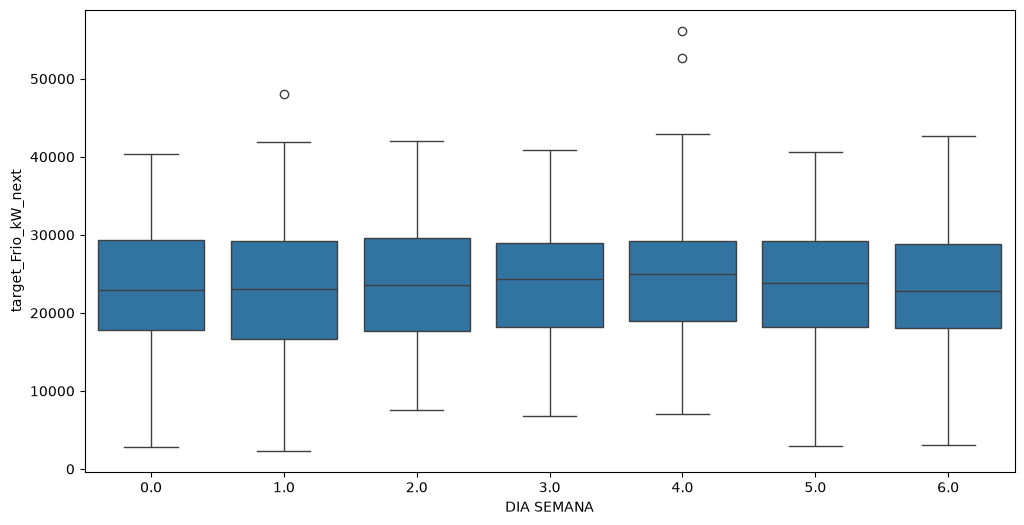

In [313]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df_diario_sin_outliers, x="DIA SEMANA",y= "target_Frio_kW_next")


In [314]:
df_diario_sin_outliers["FIN DE SEMANA"] = df_diario_sin_outliers["DIA SEMANA"] >= 5 

<Axes: xlabel='FIN DE SEMANA', ylabel='target_Frio_kW_next'>

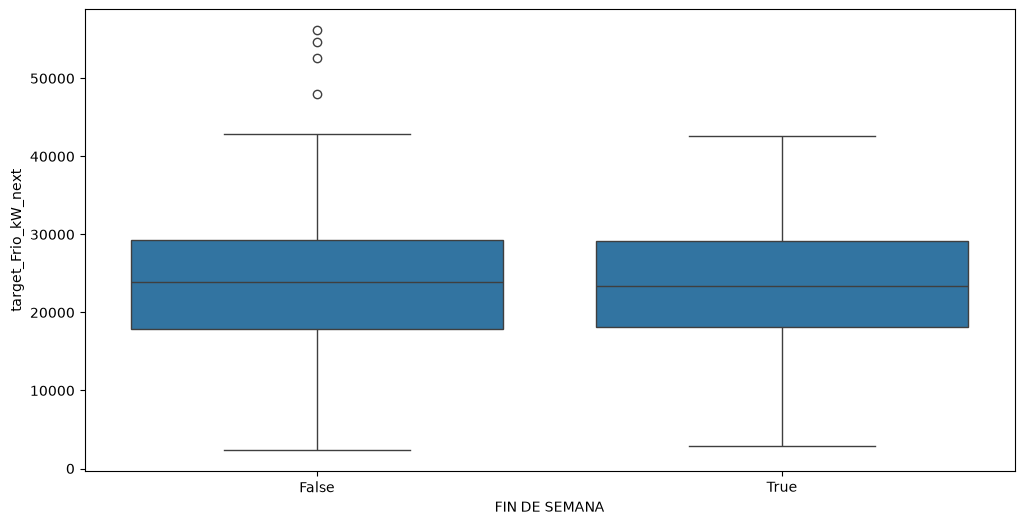

In [315]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df_diario_sin_outliers, x="FIN DE SEMANA", y= "target_Frio_kW_next")


In [316]:
df_diario_sin_outliers = df_diario_sin_outliers.drop(columns="DIA SEMANA")

In [317]:
df_diario_sin_outliers = df_diario_sin_outliers.drop(columns="FIN DE SEMANA")

### Mes del año.

<Axes: xlabel='MES', ylabel='target_Frio_kW_next'>

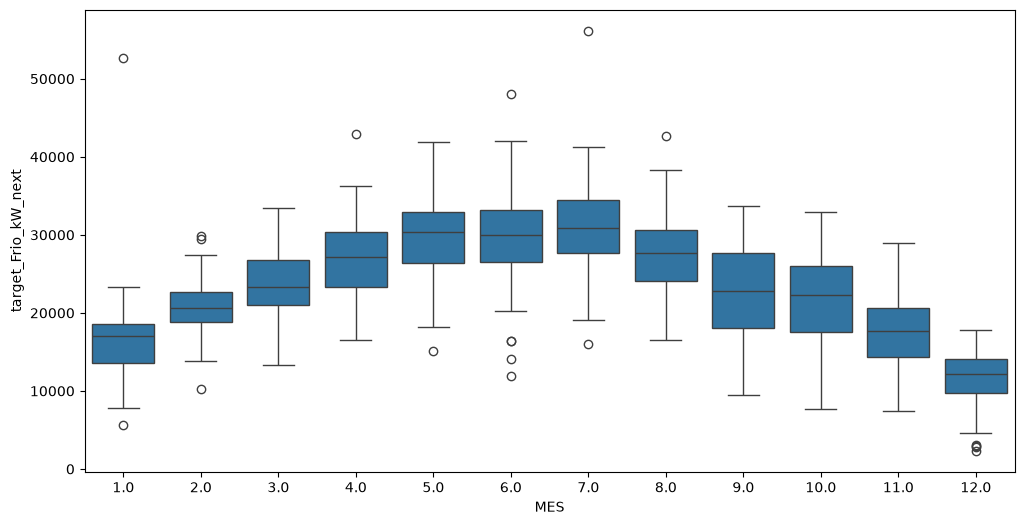

In [318]:
df_diario_sin_outliers["MES"] = df_diario_sin_outliers["DIA"].dt.month

plt.figure(figsize=(12,6))
sns.boxplot(data=df_diario_sin_outliers, x="MES", y= "target_Frio_kW_next")

Estacionariedad, se mantiene la variable MES

In [319]:
df_diario_sin_outliers.columns

Index(['EE Frio / Hl', 'KW Bba Glicol Sala MAq', 'KW Bba Glicol Bod',
       'Hl de Mosto', 'Hl Producido Bodega', 'Hl Cerveza Filtrada',
       'Hl Cerveza Envasada', 'Hl Cerveza Cocina', 'Elaboracion (Kw)',
       'Bodega (Kw)', 'Envasado (Kw)', 'Servicios (Kw)', 'Frio (Kw)',
       'Agua Planta (Hl)', 'Temp Tq Intermedio', 'Gas Planta (Mj)',
       'Vapor Elaboracion (Kg)', 'Totalizador_Bodega', 'Totalizador_Tq_Pulmon',
       'Tot  Trasiego', 'Agua Cond REC', 'KW Gral Planta', 'Planta (Kw)',
       'Sala Maq (Kw)', 'KW Cond 5. 6 y 9', 'Produccion (Hl)',
       'Aire Producido (M3)', 'Totalizador Sistema Kaeser',
       'target_Frio_kW_next', 'Kw Mycom Mean', 'Kw Trafo Mean', 'DIA', 'MES'],
      dtype='str')

In [320]:
df_diario_sin_outliers["DIA DEL MES"] = df_diario_sin_outliers["DIA"].dt.day
df_diario_sin_outliers["SEMANA"] = (df_diario_sin_outliers["DIA DEL MES"] - 1 ) // 7 + 1

<Axes: xlabel='SEMANA', ylabel='target_Frio_kW_next'>

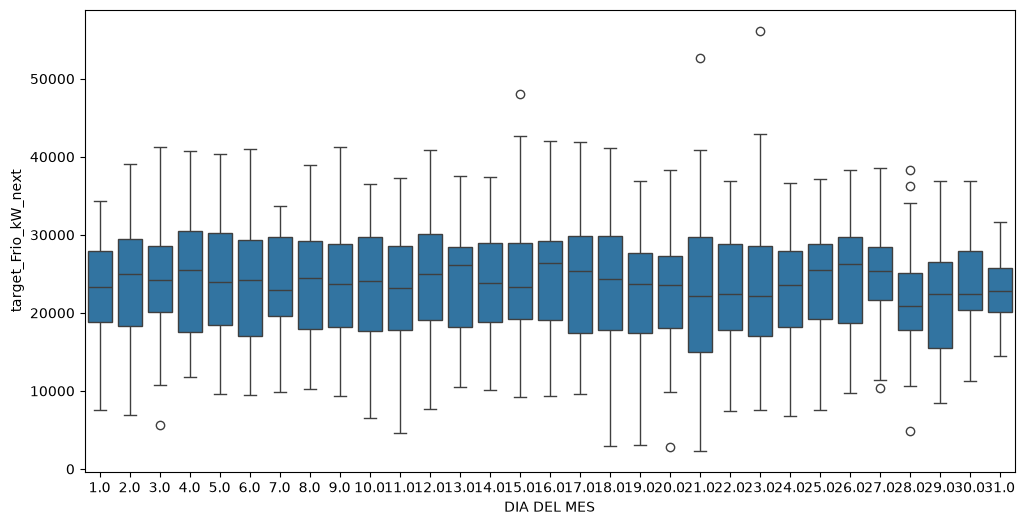

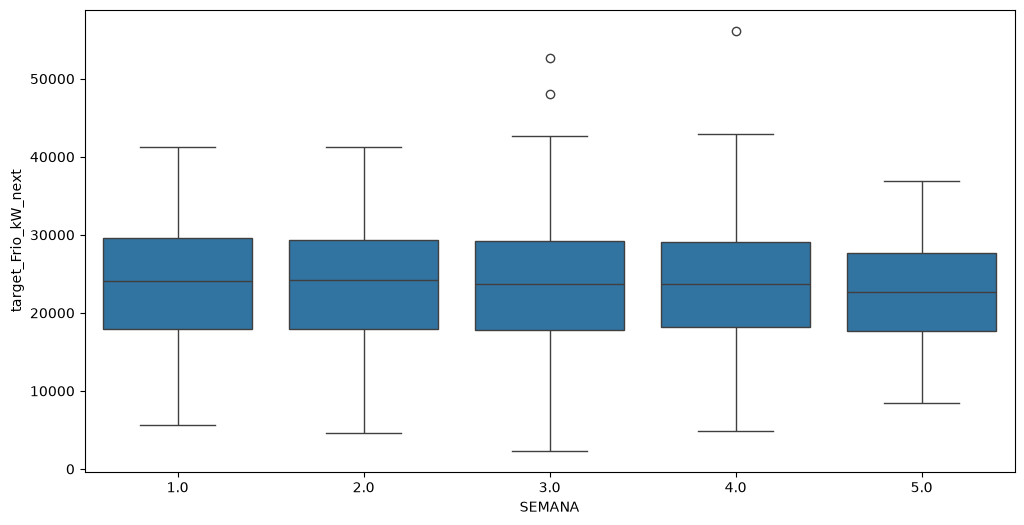

In [321]:
plt.figure(figsize=(12,6))
sns.boxplot(data=df_diario_sin_outliers, x="DIA DEL MES", y= "target_Frio_kW_next")
plt.figure(figsize=(12,6))
sns.boxplot(data=df_diario_sin_outliers, x="SEMANA", y= "target_Frio_kW_next")

No se perciben cambios por semana ni día :)

### Variable de lag

In [322]:
fecha_pasada = pd.to_datetime(df_diario_sin_outliers["DIA"].shift(7))
fecha_actual = pd.to_datetime(df_diario_sin_outliers["DIA"])
diferencia_dia_pasado = fecha_actual - fecha_pasada

df_diario_sin_outliers['Frio lag last week'] = df_diario_sin_outliers['Frio (Kw)'].shift(7)
indices_a_borrar = df_diario_sin_outliers.index[diferencia_dia_pasado > pd.Timedelta(days=7)]
df_diario_sin_outliers.loc[indices_a_borrar, 'Frio lag last week'] = None 



### Promedio Móvil

In [323]:
#ts_data['rolling_mean_7'] = ts_data['passengers'].rolling(window=7).mean()
#ts_data['sin_day_of_year'] = np.sin(2 * np.pi * ts_data.index.dayofyear / 365)
#ts_data['cos_day_of_year'] = np.cos(2 * np.pi * ts_data.index.dayofyear / 365)

df_diario_sin_outliers["Prom movil Frio"] = df_diario_sin_outliers["Frio (Kw)"].rolling(window=7).mean()


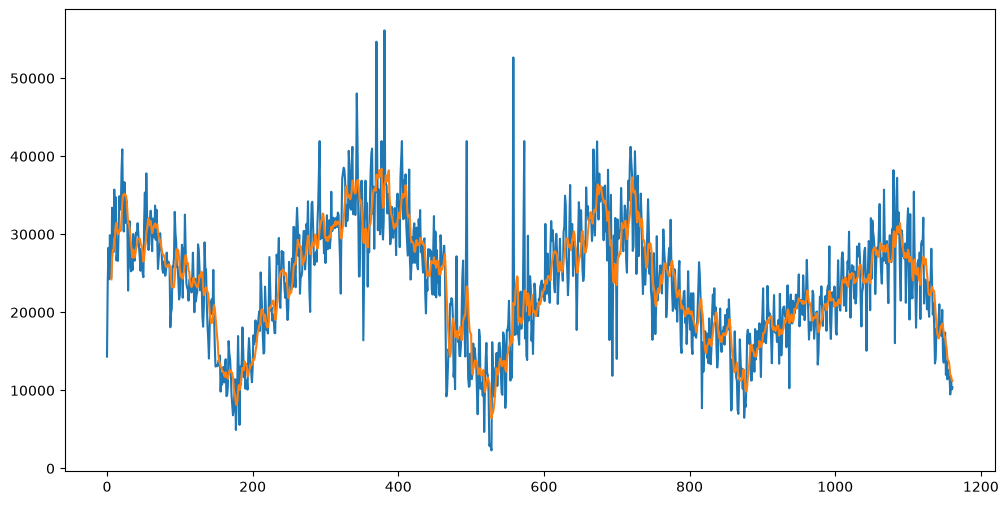

In [324]:
plt.figure(figsize=(12,6))
plt.plot(df_diario_sin_outliers["Frio (Kw)"])
plt.plot(df_diario_sin_outliers["Prom movil Frio"])

In [325]:
df_diario_sin_outliers['sin_month_of_year'] = np.sin(2 * np.pi * df_diario_sin_outliers["MES"] / 12)
df_diario_sin_outliers['cos_month_of_year'] = np.cos(2 * np.pi * df_diario_sin_outliers["MES"] / 12)


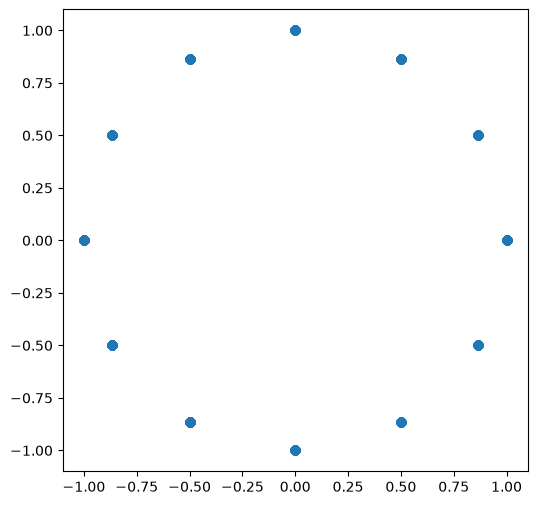

In [326]:
plt.figure(figsize=(6,6))
plt.scatter(df_diario_sin_outliers['sin_month_of_year'],df_diario_sin_outliers['cos_month_of_year'])


In [327]:
df_diario_sin_outliers.columns

Index(['EE Frio / Hl', 'KW Bba Glicol Sala MAq', 'KW Bba Glicol Bod',
       'Hl de Mosto', 'Hl Producido Bodega', 'Hl Cerveza Filtrada',
       'Hl Cerveza Envasada', 'Hl Cerveza Cocina', 'Elaboracion (Kw)',
       'Bodega (Kw)', 'Envasado (Kw)', 'Servicios (Kw)', 'Frio (Kw)',
       'Agua Planta (Hl)', 'Temp Tq Intermedio', 'Gas Planta (Mj)',
       'Vapor Elaboracion (Kg)', 'Totalizador_Bodega', 'Totalizador_Tq_Pulmon',
       'Tot  Trasiego', 'Agua Cond REC', 'KW Gral Planta', 'Planta (Kw)',
       'Sala Maq (Kw)', 'KW Cond 5. 6 y 9', 'Produccion (Hl)',
       'Aire Producido (M3)', 'Totalizador Sistema Kaeser',
       'target_Frio_kW_next', 'Kw Mycom Mean', 'Kw Trafo Mean', 'DIA', 'MES',
       'DIA DEL MES', 'SEMANA', 'Frio lag last week', 'Prom movil Frio',
       'sin_month_of_year', 'cos_month_of_year'],
      dtype='str')

### Creación de Variables mediante PolynomialFeature

In [328]:
var_def = ["Bodega (Kw)","Envasado (Kw)","Servicios (Kw)","Elaboracion (Kw)","Planta (Kw)"]

In [329]:
poly = PolynomialFeatures(degree=2, include_bias=False , interaction_only=False)

poly_features = poly.fit_transform(df_diario_sin_outliers[var_def])
poly_feature_names = poly.get_feature_names_out(var_def)

df_poly = pd.DataFrame(poly_features, columns=poly_feature_names)

print(f"\nCaracterísticas polinómicas generadas: {len(poly_feature_names)}")
print("Nuevas características (interacciones y cuadráticas):")

new_features = [name for name in poly_feature_names if name not in var_def]
display(new_features)

df_poly = df_poly[new_features].set_index(df_diario_sin_outliers.index)
df_diario_sin_outliers = pd.concat([df_diario_sin_outliers,df_poly],axis=1)


Características polinómicas generadas: 20
Nuevas características (interacciones y cuadráticas):


['Bodega (Kw)^2',
 'Bodega (Kw) Envasado (Kw)',
 'Bodega (Kw) Servicios (Kw)',
 'Bodega (Kw) Elaboracion (Kw)',
 'Bodega (Kw) Planta (Kw)',
 'Envasado (Kw)^2',
 'Envasado (Kw) Servicios (Kw)',
 'Envasado (Kw) Elaboracion (Kw)',
 'Envasado (Kw) Planta (Kw)',
 'Servicios (Kw)^2',
 'Servicios (Kw) Elaboracion (Kw)',
 'Servicios (Kw) Planta (Kw)',
 'Elaboracion (Kw)^2',
 'Elaboracion (Kw) Planta (Kw)',
 'Planta (Kw)^2']

## Pipeline de preprocesamiento

In [330]:
idx_outliers_target = df_diario[(df_diario["target_Frio_kW_next"] > 1e6) | (df_diario["Frio (Kw)"] > 1e6)].index
df_diario = df_diario.drop(index=idx_outliers_target)

In [ ]:
df_diario["DIA"] = pd.to_datetime(df_diario["DIA"])
df_diario["MES"] = df_diario["DIA"].dt.month

fecha_pasada = pd.to_datetime(df_diario["DIA"].shift(7))
fecha_actual = pd.to_datetime(df_diario["DIA"])
diferencia_dia_pasado = fecha_actual - fecha_pasada

df_diario['Frio lag last week'] = df_diario['Frio (Kw)'].shift(7)
indices_a_borrar = df_diario.index[diferencia_dia_pasado > pd.Timedelta(days=7)]
df_diario.loc[indices_a_borrar, 'Frio lag last week'] = None 



df_diario["Prom movil Frio"] = df_diario["Frio (Kw)"].rolling(window=7).mean()

df_diario['sin_month_of_year'] = np.sin(2 * np.pi * df_diario["MES"] / 12)
df_diario['cos_month_of_year'] = np.cos(2 * np.pi * df_diario["MES"] / 12)


In [332]:
df_diario = df_diario.drop(columns=["MES","DIA"])

In [333]:
X = df_diario.drop(columns="target_Frio_kW_next")
y = df_diario["target_Frio_kW_next"]

#train los más viejos, test los más nuevos
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state= 42, train_size=0.85, shuffle=False)
X_train, X_val, y_train, y_val = train_test_split(X_train, y_train, random_state=42, train_size=0.70/0.85, shuffle=False) 

In [334]:
X_train.columns

Index(['EE Frio / Hl', 'KW Bba Glicol Sala MAq', 'KW Bba Glicol Bod',
       'Hl de Mosto', 'Hl Producido Bodega', 'Hl Cerveza Filtrada',
       'Hl Cerveza Envasada', 'Hl Cerveza Cocina', 'Elaboracion (Kw)',
       'Bodega (Kw)', 'Envasado (Kw)', 'Servicios (Kw)', 'Frio (Kw)',
       'Agua Planta (Hl)', 'Temp Tq Intermedio', 'Gas Planta (Mj)',
       'Vapor Elaboracion (Kg)', 'Totalizador_Bodega', 'Totalizador_Tq_Pulmon',
       'Tot  Trasiego', 'Agua Cond REC', 'KW Gral Planta', 'Planta (Kw)',
       'Sala Maq (Kw)', 'KW Cond 5. 6 y 9', 'Produccion (Hl)',
       'Aire Producido (M3)', 'Totalizador Sistema Kaeser', 'Kw Mycom Mean',
       'Kw Trafo Mean', 'Frio lag last week', 'Prom movil Frio',
       'sin_month_of_year', 'cos_month_of_year'],
      dtype='str')

In [363]:
features_creation = ColumnTransformer(
    transformers= [
        ("Poly", PolynomialFeatures(degree=2,include_bias=False, interaction_only=False), var_def) 
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

preprocesamiento = Pipeline(steps=[
    ("Imputacion", KNNImputer(n_neighbors=5).set_output(transform="pandas")),
    ("Features_creation", features_creation.set_output(transform="pandas")),
    ("Escalado", RobustScaler().set_output(transform="pandas"))
])


Pipeline_forest = Pipeline(steps=[
    ('preprocesamiento', preprocesamiento),
    ('modelo', RandomForestRegressor())
])


Pipeline_forest.fit(X_train, y_train)
y_pred = Pipeline_forest.predict(X_val)
score = Pipeline_forest.score(X_val, y_val)
print(f"R no cuadrado: {score} ")


#error cuadrático medio
mse = ((y_val- y_pred) ** 2).mean()
rmse = float(mse ** 0.5)
print(f"RMSE en Test (pipeline sin Grid): {rmse:.2f}")

R no cuadrado: 0.41070495111266536 
RMSE en Test (pipeline sin Grid): 3046.10


In [388]:
features_forest = Pipeline_forest[-1].feature_names_in_
importancias_forest = Pipeline_forest[-1].feature_importances_

In [389]:
forest_features_importance = pd.DataFrame({"features" : features_forest, 
                                           "importancias" : importancias_forest})
forest_features_importance

,features,importancias
0,Bodega (Kw),0.002513
1,Envasado (Kw),0.001860
2,Servicios (Kw),0.035323
3,Elaboracion (Kw),0.002801
4,Planta (Kw),0.002101
5,Bodega (Kw)^2,0.002987
6,Bodega (Kw) Envasado (Kw),0.004408
7,Bodega (Kw) Servicios (Kw),0.003955
8,Bodega (Kw) Elaboracion (Kw),0.003803
9,Bodega (Kw) Planta (Kw),0.003211


In [362]:
features_creation = ColumnTransformer(
    transformers= [
        ("Poly", PolynomialFeatures(degree=2,include_bias=False, interaction_only=False), var_def) 
    ],
    remainder="passthrough",
    verbose_feature_names_out=False
)

preprocesamiento = Pipeline(steps=[
    ("Imputacion", KNNImputer(n_neighbors=5).set_output(transform="pandas")),
    ("Features_creation", features_creation.set_output(transform="pandas")),
    ("Escalado", RobustScaler().set_output(transform="pandas"))
])


Pipeline_lasso = Pipeline(steps=[
    ('preprocesamiento', preprocesamiento),
    ('modelo', LassoCV(cv=5, random_state=42))
])


Pipeline_lasso.fit(X_train, y_train)
y_pred = Pipeline_lasso.predict(X_val)
score = Pipeline_lasso.score(X_val, y_val)
print(f"R no cuadrado: {score} ")


#error cuadrático medio
mse = ((y_val- y_pred) ** 2).mean()
rmse = float(mse ** 0.5)
print(f"RMSE en Test (pipeline sin Grid): {rmse:.2f}")

R no cuadrado: -0.05860827999676954 
RMSE en Test (pipeline sin Grid): 4082.68
